# 06 · Regime map and XGBoost diagnostic

Reproduces the two ML/regime figures of the paper:

* `ml_sweep_and_importance_1x3_20260523_115442.png` (threshold sweep + feature importance)
* `regime_scatter_density_dmax_labels_cbrt_all_shaded_custom_t25_bubble_01_hybrid_20260522_003913.png`

and the leave-one-dataset-out table quoted in the text (`logo_validation_*.csv`).

The code cells below are the May 2026 analysis cells these outputs depend on, unchanged except: input paths, output folder
(`results/derived/ml_<campaign>/`, so saved results are never overwritten), and fixed
timestamps in the file names. No mining is executed; XGBoost is retrained (seed 42).

Known methodological limits of this saved analysis: random folds, tolerance selected on all data,
failure imputation rules, label naming. They are reproduced here as they were, not
fixed, so the paper's numbers can be checked.

In [1]:
# ---- bundle configuration (same cell in every notebook) ----
import os, sys, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd

BUNDLE = Path.cwd().resolve().parent          # notebooks run from <bundle>/notebooks
assert (BUNDLE / "bench" / "baseline_runners.py").exists(), f"start Jupyter in <bundle>/notebooks (cwd={Path.cwd()})"
sys.path.insert(0, str(BUNDLE / "bench"))
DATA = Path(os.environ.get("FA_DATA_DIR", BUNDLE / "data"))
RESULTS = BUNDLE / "results"
DERIVED = RESULTS / "derived"                       # regenerated statistics, tables and figures

MAY = "campaign_2026-05"                           # the April/May 2026 GCE campaign
MAY_DIR = RESULTS / MAY
CAMPAIGN = os.environ.get("FA_CAMPAIGN", MAY) # set FA_CAMPAIGN=<id> to analyse a new run
CAMPAIGN_DIR = MAY_DIR if CAMPAIGN == MAY else RESULTS / "runs" / CAMPAIGN
AGG_CSV = (MAY_DIR / "results_rigorous_20260523_115442.csv" if CAMPAIGN == MAY
           else CAMPAIGN_DIR / f"results_rigorous_{CAMPAIGN}.csv")
LCM_CSV = MAY_DIR / "lcm_declat_results_20260523_055523.csv"
COST_CSV = (DERIVED / "cost_stats.csv") if (DERIVED / "cost_stats.csv").exists() else MAY_DIR / "cost_stats_20261022.csv"

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def rel(p):
    try:
        return Path(p).resolve().relative_to(BUNDLE).as_posix()
    except ValueError:
        return str(p)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print(f"campaign : {CAMPAIGN}\nagg csv  : {rel(AGG_CSV)}")

campaign : campaign_2026-05
agg csv  : results/campaign_2026-05/results_rigorous_20260523_115442.csv


In [2]:
ML_OUT = DERIVED / f"ml_{CAMPAIGN}"; ML_OUT.mkdir(parents=True, exist_ok=True)
OUT_DIR = ML_OUT
# file-name stamps: the May 2026 figures were produced in two kernel sessions
TS = "20260523_115442" if CAMPAIGN == MAY else CAMPAIGN
TS_REGIME = "20260522_003913" if CAMPAIGN == MAY else CAMPAIGN
print("outputs ->", rel(ML_OUT))

outputs -> results/derived/ml_campaign_2026-05


## Imports

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
from pathlib import Path
import baseline_runners as br
import time

# One timestamp per notebook execution. Every CSV/PNG/PDF written below
# is suffixed with this so re-runs don't overwrite previous artifacts.
print(f'stamp: {TS}')

stamp: 20260523_115442


## Inputs
May 2026 campaign: the raw rows are read from the Excel workbook of the May 2026 analysis, and the
aggregate is the saved CSV that `03_aggregate.ipynb` verified to equal `br.aggregate(raw)`.

In [4]:
if CAMPAIGN == MAY:
    raw = pd.read_excel(MAY_DIR / "intermediate" / "output_raw_fast_v5_29.4.xlsx")
else:
    raw = pd.concat([pd.read_csv(f) for f in sorted((CAMPAIGN_DIR / "raw").glob("*.csv"))], ignore_index=True)
agg = pd.read_csv(AGG_CSV, low_memory=False)
print(f"raw rows: {len(raw):,} | aggregated configurations: {len(agg):,}")

raw rows: 19,628 | aggregated configurations: 4,891


## Plot configuration and helpers

In [5]:
# Methods drawn as hollow-marker variants (paired with a sibling method that
# shares the same color). `fastapriori_fast_1t` pairs with `fastapriori_fast`.
PAIRED_HOLLOW = {"fastapriori_fast_1t"}

In [6]:
# Drop these methods from every plot. Add/remove as needed.
# Example: hide all SPMF-flavoured runs because they dominate on one dataset.
METHODS_EXCLUDE = {
    # "spmf_fpgrowth", "spmf_eclat",
    # "spmf_py_fpgrowth", "spmf_py_eclat",
    # "borgelt_apriori", "borgelt_eclat",
    # "efficient_apriori",
}

# Per-family strategy. Keys are method-name prefixes (before the first '_'
# after the family name). Values:
#   None                      -- show every variant as its own curve
#   "min"                     -- one curve per family = min wall time across variants
#   "median"                  -- one curve per family = median wall time across variants
#   "drop"                    -- drop the whole family
#   "<full_method_name>"      -- keep only that one variant from the family
FAMILY_STRATEGY = {
    "pyfim":   "median",       # collapse pyfim_apriori/fpgrowth/eclat into "pyfim (best)"
    "borgelt": "drop",        # show all three Borgelt binaries
    "spmf":    "min",      # hide SPMF java entirely (reinstate if you want it)
    "spmf_py": "drop",
}

# Styling: method -> (color, marker). Unlisted methods get an auto color.
STYLE = {
    "fastapriori_fast":    ("#FF5C00", "o"),
    "fastapriori_fast_1t": ("#FF5C00", "o"),  # paired: same color, hollow marker
    "fastapriori_classic": ("#2980B9",   "v"),
    "efficient_apriori":   ("tab:red",    "^"),
    "pyfim (best)":        ("tab:purple",  "D"),
    "pyfim (median)":      ("tab:purple",  "s"),
    "borgelt_apriori":     ("tab:purple", "v"),
    "borgelt_fpgrowth":    ("tab:brown",  "P"),
    "borgelt_eclat":       ("tab:pink",   "X"),
    "borgelt (best)":      ("tab:purple", "v"),
    "spmf_fpgrowth":       ("tab:olive",  "*"),
    "spmf_eclat":          ("tab:cyan",   "h"),
    "spmf_py_fpgrowth":    ("tab:olive",  "p"),
    "spmf_py_eclat":       ("tab:cyan",   "H"),
}

# Save location.
print(f"Plots -> {OUT_DIR}")

Plots -> <artifacts>\results\derived\ml_campaign_2026-05


In [7]:
label_map= {"fastapriori_fast":"fast", "fastapriori_fast_1t": "fast_1T", "fastapriori_classic": "classic"}

In [8]:
label_map= {"fastapriori_fast":"hyfim", "fastapriori_fast_1t": "hyfim_1T", "fastapriori_classic": "classic"}

In [9]:
def apply_family_strategy(df_, strategy):
    """For each family in `strategy`, collapse/drop variants per the rule.
    Returns a new DataFrame with the same columns (method may be rewritten
    to a synthetic 'family (best)' name)."""
    out = df_.copy()
    for family, rule in strategy.items():
        prefix = family + "_"
        fam_mask = out["method"].str.startswith(prefix)
        fam = out[fam_mask]
        rest = out[~fam_mask]
        if rule is None or fam.empty:
            continue
        if rule == "drop":
            out = rest
            continue
        if isinstance(rule, str) and rule.startswith(prefix):
            # keep a single specific variant
            out = pd.concat([rest, fam[fam["method"] == rule]], ignore_index=True)
            continue
        if rule in ("min", "median"):
            agg_fn = {"min": "min", "median": "median"}[rule]
            keys = ["dataset", "k", "min_support"]
            # Aggregate wall_s_median across variants; carry q25/q75 as the
            # extremes of the surviving variant's IQR (not a true percentile
            # of the collapsed distribution, but honest enough for visuals).
            g = (fam.groupby(keys)
                    .agg(wall_s_median=("wall_s_median", agg_fn),
                         wall_s_q25=("wall_s_q25", "min"),
                         wall_s_q75=("wall_s_q75", "max"),
                         peak_rss_kb_median=("peak_rss_kb_median", agg_fn),
                         peak_rss_kb_q25=("peak_rss_kb_q25", "min"),
                         peak_rss_kb_q75=("peak_rss_kb_q75", "max"),
                         n_runs_total=("n_runs_total", "sum"))
                    .reset_index())
            g["method"] = f"{family} ({rule if rule != 'min' else 'best'})"
            g["algo"]   = rule
            out = pd.concat([rest, g], ignore_index=True)
            continue
        raise ValueError(f"Unknown strategy {rule!r} for family {family!r}")
    return out


def prepare(df_, k, methods_exclude=None, family_strategy=None):
    d = df_[df_["k"] == k].copy()
    if methods_exclude:
        d = d[~d["method"].isin(methods_exclude)]
    if family_strategy:
        d = apply_family_strategy(d, family_strategy)
    # Drop any rows with no median wall (shouldn't happen in aggregated CSV).
    d = d.dropna(subset=["wall_s_median"])
    return d


def plot_grid(data, k, cols=2, error_bars=True, title=None, save=None):
    method_order = [
        "efficient_apriori",
        "fastapriori_classic",
        "fastapriori_fast_1t",
        "fastapriori_fast",
        "pyfim (best)",
        "pyfim (median)",
    ]
    def _rank(m):
        return (method_order.index(m), m) if m in method_order else (len(method_order), m)
    datasets = sorted(data["dataset"].unique())
    n = len(datasets)
    if n == 0:
        print(f"No rows at k={k}")
        return None
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows),
                             squeeze=False)
    methods_seen = []
    for i, (ax, ds) in enumerate(zip(axes.flat, datasets)):
        is_first_col = (i % cols) == 0
        is_bottom = (i + cols) >= n
        sub = data[data["dataset"] == ds]
        for method in sorted(sub["method"].unique(), key=_rank, reverse=True):
            m = sub[sub["method"] == method].sort_values("min_support")
            color, marker = STYLE.get(method, (None, "o"))
            kw = dict(marker=marker, label=method, linewidth=1.3, markersize=5)
            if color is not None:
                kw["color"] = color
            if method in PAIRED_HOLLOW:
                kw["markerfacecolor"] = "white"
                kw["markeredgewidth"] = 1.2
            ax.plot(m["min_support"], m["wall_s_median"], **kw)
            if error_bars and "wall_s_q25" in m.columns and "wall_s_q75" in m.columns:
                ax.fill_between(m["min_support"], m["wall_s_q25"], m["wall_s_q75"],
                                alpha=0.12, color=kw.get("color", None),
                                linewidth=0)
            if method not in methods_seen:
                methods_seen.append(method)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(ds, fontsize=11, fontweight='bold')
        if is_bottom:
            ax.set_xlabel("min_support", fontsize=10)
        if is_first_col:
            ax.set_ylabel("Time (s)", fontsize=10)
        ax.grid(True, which="major", alpha=0.5, linewidth=0.5)
        ax.minorticks_off()
        # ax.grid(False, which="minor")
        # ax.yaxis.set_major_locator(LogLocator(base=10, subs="auto", numticks=8))
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    # Figure-level legend: gather unique (handle, label) across subplots,
    # reorder by method_order, and draw once outside the grid.
    _handles, _labels = [], []
    _seen = set()
    for _ax in axes.flat[:n]:
        for _h, _l in zip(*_ax.get_legend_handles_labels()):
            if _l not in _seen:
                _seen.add(_l); _handles.append(_h); _labels.append(_l)

    # Rank on full method names (what _rank/method_order know about),
    # then remap to display labels only at legend-render time.
    _order = sorted(range(len(_labels)), key=lambda i: _rank(_labels[i]))
    _display = [label_map.get(_labels[i], _labels[i]) for i in _order]
    fig.legend([_handles[i] for i in _order], _display,
               loc="upper center", bbox_to_anchor=(0.5, 1.02),
               ncol=min(len(_labels), 5), fancybox=True, fontsize=10)
    if title:
        fig.suptitle(title, y=1.02, fontsize=13, fontweight="bold")
    fig.tight_layout()
    if save:
        # `save` is a stem path (no extension). Build `<stem>_<TS>.<ext>` via
        # with_name so it works regardless of whether the caller's path has a
        # dot in it â€” Path.with_suffix() here was buggy because time.time()
        # returns a float (embedded '.') and suffixes must start with '.'.
        save = Path(save)
        for ext in ("png",):
            out_path = save.with_name(f"{save.name}_med_{TS}.{ext}")
            fig.savefig(out_path, dpi=140, bbox_inches="tight")
            print(f"Saved {out_path}")
    return fig

In [10]:
def plot_grid_mem(data, k, cols=2, error_bars=False, title=None, save=None):
    method_order = [
        "efficient_apriori",
        "fastapriori_classic",
        "fastapriori_fast_1t",
        "fastapriori_fast",
        "pyfim (best)",
        "pyfim (median)",
    ]
    def _rank(m):
        return (method_order.index(m), m) if m in method_order else (len(method_order), m)
    datasets = sorted(data["dataset"].unique())
    n = len(datasets)
    if n == 0:
        print(f"No rows at k={k}")
        return None
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5.5 * cols, 3.4 * rows),
                             squeeze=False)
    methods_seen = []
    for i, (ax, ds) in enumerate(zip(axes.flat, datasets)):
        is_first_col = (i % cols) == 0
        is_bottom = (i + cols) >= n
        sub = data[(data["dataset"] == ds) & data["peak_rss_kb_median"].notna()]
        for method in sorted(sub["method"].unique(), key=_rank, reverse=True):
            m = sub[sub["method"] == method].sort_values("min_support")
            if m.empty:
                continue
            color, marker = STYLE.get(method, (None, "o"))
            kw = dict(marker=marker, label=method, linewidth=1.3, markersize=5)
            if color is not None:
                kw["color"] = color
            if method in PAIRED_HOLLOW:
                kw["markerfacecolor"] = "white"
                kw["markeredgewidth"] = 1.2
            ax.plot(m["min_support"], m["peak_rss_kb_median"] / 1024, **kw)
            if error_bars and "peak_rss_kb_q25" in m.columns and "peak_rss_kb_q75" in m.columns:
                ax.fill_between(m["min_support"],
                                m["peak_rss_kb_q25"] / 1024,
                                m["peak_rss_kb_q75"] / 1024,
                                alpha=0.12, color=kw.get("color", None),
                                linewidth=0)
            if method not in methods_seen:
                methods_seen.append(method)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(ds, fontsize=11)
        if is_bottom:
            ax.set_xlabel("min_support", fontsize=11)
        if is_first_col:
            ax.set_ylabel("Peak RSS (MB)", fontsize=11)
        ax.grid(True, which="major", alpha=0.5, linewidth=0.5)
        ax.grid(False, which="minor")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs="auto", numticks=8))
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    # Figure-level legend: gather unique (handle, label) across subplots,
    # reorder by method_order, and draw once outside the grid.
    _handles, _labels = [], []
    _seen = set()
    for _ax in axes.flat[:n]:
        for _h, _l in zip(*_ax.get_legend_handles_labels()):
            if _l not in _seen:
                _seen.add(_l); _handles.append(_h); _labels.append(_l)
    # Rank on full method names, then remap to display labels only for the legend.
    _order = sorted(range(len(_labels)), key=lambda i: _rank(_labels[i]))
    _display = [label_map.get(_labels[i], _labels[i]) for i in _order]
    fig.legend([_handles[i] for i in _order], _display,
               loc="upper center", bbox_to_anchor=(0.5, 1.000001),
               ncol=min(len(_labels), 5), fontsize=10, fancybox= True)
    if title:
        fig.suptitle(title, y=1.02, fontsize=12, fontweight="bold")
    fig.tight_layout()
    if save:
        save = Path(save)
        for ext in ("png",):
            out_path = save.with_name(f"{save.name}_mem_{TS}.{ext}")
            fig.savefig(out_path, dpi=140, bbox_inches="tight")
            print(f"Saved {out_path}")
    return fig

## Failure imputation used by the ML labels

In [11]:
df = agg.copy()

# ============================================================
# Backfill / failure-mode imputation for fast vs classic
# ============================================================
# Two policies:
#
# (A) efficient_apriori: backfill missing rows with the actual measured wall_s
#     at the failure (so the heatmap shows EA's real timeout/OOM time).
#
# (B) fastapriori_fast / fastapriori_classic: apply explicit win-attribution
#     rules so the ML model and heatmap see the failure-mode regimes correctly.
#
#     For every (dataset, k, min_support) cell where fast or classic has
#     non-OK status (timeout/oom):
#       - on DATASETS_FAVORING_CLASSIC = {OR, Kosarak, BMS-WebView-1}:
#           * fast OOM (regardless of classic status)        -> classic wins
#           * both timeout                                    -> classic wins
#           * classic timeout, fast OK                        -> classic = 1500 (fast wins on time)
#           * fast timeout, classic OK                        -> fast = 1500 (classic wins)
#         When "classic wins" but no real classic OK runs exist at that cell,
#         use a sentinel (CLASSIC_WIN_SENTINEL_S) so ratio = classic/fast
#         shows a clear classic-color cell.
#       - other datasets: timeout/oom -> wall_s = TIMEOUT_PENALTY_S (1500)
#
# pyfim_*: never backfilled (treating its timeouts as real measurements would
# bias "pyfim_best" toward misleading lowest-support picks).

TIMEOUT_PENALTY_S      = 1500.0   # one method failed, the other completed
CLASSIC_WIN_SENTINEL_S = 500.0    # synthetic classic wall for "classic wins"
                                  # when no real classic OK time exists
DATASETS_FAVORING_CLASSIC = {"Online Retail", "Kosarak", "BMS-WebView-1"}
_FAILED_STATUSES = {"timeout", "oom"}

# ---- (A) Backfill efficient_apriori with raw wall_s -------------------
_fill_cols = ["wall_s", "peak_rss_kb"]

def _has_failure_only(rows):
    if rows.empty:
        return False
    s = set(rows["status"].dropna().astype(str).unique())
    return ("ok" not in s) and bool(s & _FAILED_STATUSES)

_missing = df["wall_s_median"].isna()
for idx in df.index[_missing]:
    method = df.at[idx, "method"]
    if method != "efficient_apriori":
        continue
    key = (df.at[idx, "dataset"], method,
           df.at[idx, "k"], df.at[idx, "min_support"])
    rows = raw[(raw["dataset"] == key[0]) & (raw["method"] == key[1])
               & (raw["k"] == key[2]) & (raw["min_support"] == key[3])]
    if not _has_failure_only(rows):
        continue
    for col in _fill_cols:
        v = rows[col].dropna().max()
        if pd.notna(v):
            df.at[idx, f"{col}_median"] = v
            df.at[idx, f"{col}_q25"] = v
            df.at[idx, f"{col}_q75"] = v

_agg_keys_ea = {(d, m, k, s) for d, m, k, s in
                zip(df["dataset"], df["method"], df["k"], df["min_support"])
                if m == "efficient_apriori"}
_raw_ea = raw[raw["method"] == "efficient_apriori"]
_raw_keys_ea = set(zip(_raw_ea["dataset"], _raw_ea["method"],
                       _raw_ea["k"], _raw_ea["min_support"]))
_new_ea = []
for key in _raw_keys_ea - _agg_keys_ea:
    rows = raw[(raw["dataset"] == key[0]) & (raw["method"] == key[1])
               & (raw["k"] == key[2]) & (raw["min_support"] == key[3])]
    if not _has_failure_only(rows):
        continue
    row = {"dataset": key[0], "method": key[1], "k": key[2], "min_support": key[3]}
    for col in _fill_cols:
        v = rows[col].dropna().max()
        if pd.notna(v):
            row[f"{col}_median"] = v
            row[f"{col}_q25"] = v
            row[f"{col}_q75"] = v
    _new_ea.append(row)
if _new_ea:
    df = pd.concat([df, pd.DataFrame(_new_ea)], ignore_index=True)

# ---- (B) Failure-mode imputation for fast / classic -------------------
if "is_imputed" not in df.columns:
    df["is_imputed"] = False

def _statuses(rows):
    if rows.empty:
        return set()
    return set(rows["status"].dropna().astype(str).unique())

# Iterate over every (dataset, k, min_support) cell that has any fast or
# classic raw rows. Decide the outcome and write/inject into df.
_fc_raw = raw[raw["method"].isin({"fastapriori_fast", "fastapriori_classic"})]
_n_imputed = 0
_n_synthetic = 0
for (ds, k, ms), grp in _fc_raw.groupby(["dataset", "k", "min_support"], sort=False):
    f_rows = grp[grp["method"] == "fastapriori_fast"]
    c_rows = grp[grp["method"] == "fastapriori_classic"]
    f_st = _statuses(f_rows)
    c_st = _statuses(c_rows)
    f_ok_med = f_rows[f_rows["status"] == "ok"]["wall_s"].median() if "ok" in f_st else None
    c_ok_med = c_rows[c_rows["status"] == "ok"]["wall_s"].median() if "ok" in c_st else None
    f_failed_only = ("ok" not in f_st) and bool(f_st & _FAILED_STATUSES)
    c_failed_only = ("ok" not in c_st) and bool(c_st & _FAILED_STATUSES)

    # Skip cells where neither side has any failure: agg already handles them.
    if not (f_failed_only or c_failed_only):
        continue

    # Decide the (fast_wall, classic_wall) imputation per the rules.
    fast_wall = None
    classic_wall = None

    if ds in DATASETS_FAVORING_CLASSIC:
        f_oom = f_failed_only and ("oom" in f_st)
        c_oom = c_failed_only and ("oom" in c_st)
        f_to  = f_failed_only and ("timeout" in f_st) and not f_oom
        c_to  = c_failed_only and ("timeout" in c_st) and not c_oom

        # Rules:
        #   memout (on these)             -> classic wins
        #   both timed out                -> classic wins
        #   only fast timed out           -> fast = 1500, classic = real
        #   only classic timed out        -> classic = 1500, fast = real
        if f_oom or c_oom or (f_to and c_to):
            fast_wall = TIMEOUT_PENALTY_S
            classic_wall = c_ok_med if c_ok_med is not None else CLASSIC_WIN_SENTINEL_S
        elif f_to and not c_failed_only:
            fast_wall = TIMEOUT_PENALTY_S
            classic_wall = c_ok_med  # classic was OK; ratio shows classic winning
        elif c_to and not f_failed_only:
            classic_wall = TIMEOUT_PENALTY_S
            fast_wall = f_ok_med     # classic timed out; fast wins on time
    else:
        # Other datasets: timeout/oom -> 1500
        if f_failed_only:
            fast_wall = TIMEOUT_PENALTY_S
        if c_failed_only:
            classic_wall = TIMEOUT_PENALTY_S

    # Memory: best-effort use the max raw peak_rss seen at this cell
    f_rss = f_rows["peak_rss_kb"].dropna().max()
    c_rss = c_rows["peak_rss_kb"].dropna().max()

    for method, wall, rss in [("fastapriori_fast",    fast_wall,    f_rss),
                              ("fastapriori_classic", classic_wall, c_rss)]:
        if wall is None or pd.isna(wall):
            continue
        mask = ((df["dataset"] == ds) & (df["method"] == method)
                & (df["k"] == k) & (df["min_support"] == ms))
        if mask.any():
            idx = df.index[mask][0]
            df.at[idx, "wall_s_median"] = wall
            df.at[idx, "wall_s_q25"]    = wall
            df.at[idx, "wall_s_q75"]    = wall
            df.at[idx, "is_imputed"]    = True
            if pd.notna(rss):
                df.at[idx, "peak_rss_kb_median"] = rss
                df.at[idx, "peak_rss_kb_q25"]    = rss
                df.at[idx, "peak_rss_kb_q75"]    = rss
            _n_imputed += 1
        else:
            new_row = {
                "dataset": ds, "method": method, "k": k, "min_support": ms,
                "wall_s_median": wall, "wall_s_q25": wall, "wall_s_q75": wall,
                "is_imputed": True,
            }
            if pd.notna(rss):
                new_row["peak_rss_kb_median"] = rss
                new_row["peak_rss_kb_q25"]    = rss
                new_row["peak_rss_kb_q75"]    = rss
            df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
            _n_synthetic += 1

print(f"Imputed (fast/classic) cells: {_n_imputed} updated + {_n_synthetic} synthesised")
print()
print("Per-dataset failure-mode imputation:")
print(df[df["is_imputed"]].groupby(["dataset", "method"]).size().to_string())

Imputed (fast/classic) cells: 1 updated + 51 synthesised

Per-dataset failure-mode imputation:
dataset                  method             
BMS-WebView-1            fastapriori_classic     3
                         fastapriori_fast        3
Groceries                fastapriori_classic     3
                         fastapriori_fast        3
Kosarak                  fastapriori_classic     5
                         fastapriori_fast        5
Online Retail            fastapriori_classic     9
                         fastapriori_fast        9
T25.I8.D5000k.N40k.L40k  fastapriori_classic    12


In [12]:
real = ['BMS-WebView-1',
 'BMS-WebView-2',
 'Chainstore',
 'Groceries',
 'Instacart',
 'Kosarak',
 'Online Retail',
 'Retail (Belgian)']

## Training table

In [13]:
# --- Build the master training table for the threshold-sweep ML models ---
# Pivot the agg DataFrame `df` so each row is one (dataset, k, min_support)
# config with columns for fast/classic/pyfim_best wall times. Then add the
# per-dataset features needed for XGBoost.
#
# Two training subsets fall out of this:
#   df_fc  = configs where both fast and classic completed (fast vs classic)
#   df_fp  = configs where both fast and pyfim_best completed (fast vs pyfim)

from math import factorial

_methods = ["fastapriori_fast", "fastapriori_classic",
            "pyfim_apriori", "pyfim_fpgrowth", "pyfim_eclat"]
# Admit OK runs and any failure-mode-imputed rows (is_imputed=True).
# The latter have wall_s_n_ok=NaN but represent failure-mode wins that
# the ML model needs to see (e.g., fast OOMs on Online Retail / Kosarak).
_method_mask = df["method"].isin(_methods)
_ok_mask = df["wall_s_n_ok"] > 0
_imputed_mask = df.get("is_imputed", pd.Series(False, index=df.index)).fillna(False).astype(bool)
_ok = df[_method_mask & (_ok_mask | _imputed_mask)].copy()

times = (_ok.pivot_table(index=["dataset", "k", "min_support"],
                         columns="method", values="wall_s_median",
                         aggfunc="median")
            .reset_index())

# pyfim_best = min wall across the three pyfim variants for the same config
_pyfim_cols = [c for c in ["pyfim_apriori", "pyfim_fpgrowth", "pyfim_eclat"]
               if c in times.columns]
times["pyfim_time"] = times[_pyfim_cols].min(axis=1)

times = times.rename(columns={
    "fastapriori_fast":    "fast_time",
    "fastapriori_classic": "classic_time",
})

# --- per-dataset features pulled from the agg CSV ---
_ds_feat = (df.groupby("dataset").agg(
    n_transactions=("n_transactions", "first"),
    n_items=("n_items", "first"),
    n_rows=("n_rows", "first"),
    d_avg=("avg_items_per_txn", "first"),
    d_median=("median_items_per_txn", "first"),
    d_max=("max_items_per_txn", "first"),
    d_std=("std_items_per_txn", "first"),
    density=("density", "first"),
).reset_index())
_ds_feat["d_CV"] = _ds_feat["d_std"] / _ds_feat["d_avg"]
_ds_feat["d_max_by_d_avg"] = _ds_feat["d_max"] / _ds_feat["d_avg"]
_ds_feat["I_est"] = _ds_feat["d_avg"].apply(lambda x: max(2, int(round(x / 2.5))))
_ds_feat["L_est"] = _ds_feat["n_items"].apply(lambda x: max(10, int(round(2 * x))))

times = times.merge(_ds_feat, on="dataset", how="left")

# --- engineered features ---
times["log_D"]            = np.log1p(times["n_transactions"])
times["log_N"]            = np.log1p(times["n_items"])
times["log_rows"]         = np.log1p(times["n_rows"])
times["log_d_avg"]        = np.log1p(times["d_avg"])
times["log_support"]      = np.log1p(times["min_support"])
times["log_I"]            = np.log1p(times["I_est"])
times["log_L"]            = np.log1p(times["L_est"])
times["k_x_d_avg"]        = times["k"] * times["d_avg"]
times["k_x_log_D"]        = times["k"] * times["log_D"]
times["d_avg_x_log_D"]    = times["d_avg"] * times["log_D"]
times["log_comb_cost"]    = np.log1p(times["d_avg"]**times["k"] / times["k"].apply(factorial))
#times["items_per_txn_ratio"] = times["n_items"]       / (times["n_transactions"] + 1)
times["txn_per_item"]     = times["n_transactions"]  / (times["n_items"] + 1)
#times["sparsity"]         = times["n_items"]         / (times["d_avg"] * times["n_transactions"])

FEATURES = [
    "log_D", "log_N", "log_rows", "log_d_avg", "log_support",
    "k", "d_avg", "d_max", "d_std",
    "log_I", "log_L",
    "k_x_d_avg", "k_x_log_D", "d_avg_x_log_D", "density",
    "log_comb_cost", "txn_per_item",
    "d_max_by_d_avg",  "d_CV",
]

df_fc = times.dropna(subset=["fast_time", "classic_time"] + FEATURES).copy()
df_fp = times.dropna(subset=["fast_time", "pyfim_time"]   + FEATURES).copy()

print(f"fast vs classic training table: {len(df_fc)} configs "
      f"({df_fc['dataset'].nunique()} datasets, k={sorted(df_fc['k'].unique())})")
print(f"fast vs pyfim   training table: {len(df_fp)} configs "
      f"({df_fp['dataset'].nunique()} datasets, k={sorted(df_fp['k'].unique())})")
print(f"Features: {len(FEATURES)}")
print()
print("Time-saved distribution (classic - fast):")
print(df_fc["classic_time"].sub(df_fc["fast_time"]).describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95]))
print()
print("Time-saved distribution (pyfim - fast):")
print(df_fp["pyfim_time"].sub(df_fp["fast_time"]).describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95]))

fast vs classic training table: 574 configs (18 datasets, k=[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)])
fast vs pyfim   training table: 601 configs (18 datasets, k=[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)])
Features: 19

Time-saved distribution (classic - fast):
count     574.000000
mean       56.236934
std       317.860139
min     -1000.000000
5%         -0.430617
25%         0.068659
50%         0.906237
75%        12.104067
90%       202.727972
95%       596.787391
max      1483.450452
dtype: float64

Time-saved distribution (pyfim - fast):
count     601.000000
mean      -27.132970
std       189.661137
min     -1495.394916
5%        -16.327936
25%        -0.737641
50%        -0.069486
75%        -0.016665
90%         0.129092
95%         3.298171
max        22.926393
dtype: float64


## Threshold sweeps

In [14]:
# --- Threshold sweep helper + run for fast vs pyfim ---
# Recommendation rule under threshold T:
#   recommend_fast = 1  if  (baseline_time - fast_time) > -T   (fast is fine)
#                  = 0  if  fast is slower than baseline by MORE than T seconds
# Bigger T => more configs labelled "recommend_fast" => simpler problem.
# We sweep T = 1..10 and pick the T that maximises MCC (handles class imbalance).

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             matthews_corrcoef, precision_score, recall_score,
                             classification_report, confusion_matrix)
import xgboost as xgb

def threshold_sweep_xgb(table, fast_col, baseline_col, label, features,
                        T_range=range(1, 11), seed=42):
    """Sweep T, train XGBoost via 5-fold stratified CV, return (sweep_df, best)."""
    work = table.copy()
    work["time_saved"] = work[baseline_col] - work[fast_col]
    X = work[features].values
    records, best = [], None

    for T in T_range:
        y = (work["time_saved"] > -T).astype(int).values
        n_pos, n_neg = int(y.sum()), int(len(y) - y.sum())
        if n_pos == 0 or n_neg == 0:
            print(f"  [{label}] T={T:2d}s skipped (single class: pos={n_pos}, neg={n_neg})")
            continue

        clf = xgb.XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8,
            random_state=seed, n_jobs=-1, eval_metric="logloss",
        )
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        y_prob = np.zeros(len(y), float)
        y_pred = np.zeros(len(y), int)
        for tr, te in cv.split(X, y):
            clf.fit(X[tr], y[tr])
            y_pred[te] = clf.predict(X[te])
            y_prob[te] = clf.predict_proba(X[te])[:, 1]

        acc   = accuracy_score(y, y_pred)
        f1    = f1_score(y, y_pred, zero_division=0)
        auroc = roc_auc_score(y, y_prob)
        mcc   = matthews_corrcoef(y, y_pred)
        prec_b = precision_score(y, y_pred, pos_label=0, zero_division=0)
        rec_b  = recall_score(y, y_pred, pos_label=0, zero_division=0)
        prec_f = precision_score(y, y_pred, pos_label=1, zero_division=0)
        rec_f  = recall_score(y, y_pred, pos_label=1, zero_division=0)

        records.append({
            "label": label, "threshold_s": T,
            "n_recommend_fast": n_pos, "n_recommend_baseline": n_neg,
            "accuracy": acc, "f1_score": f1, "auroc": auroc, "mcc": mcc,
            "precision_baseline": prec_b, "recall_baseline": rec_b,
            "precision_fast": prec_f, "recall_fast": rec_f,
        })

        if best is None or mcc > best["mcc"]:
            best = {"T": T, "y": y, "y_pred": y_pred, "y_prob": y_prob,
                    "mcc": mcc, "X": X, "table": work}

        print(f"  [{label}] T={T:2d}s  acc={acc:.3f}  f1={f1:.3f}  "
              f"auroc={auroc:.3f}  mcc={mcc:.3f}  "
              f"(rec_fast={n_pos}/{len(y)})")

    sweep = pd.DataFrame(records)
    return sweep, best


print("=== Threshold sweep: fast vs pyfim_best ===")
sweep_fp, best_fp = threshold_sweep_xgb(
    df_fp, fast_col="fast_time", baseline_col="pyfim_time",
    label="fast_vs_pyfim", features=FEATURES)
sweep_fp.to_csv(ML_OUT / "threshold_sweep_fast_vs_pyfim.csv", index=False)
print(f"\nSaved threshold_sweep_fast_vs_pyfim.csv  "
      f"(best MCC = {best_fp['mcc']:.3f} at T = {best_fp['T']}s)")

=== Threshold sweep: fast vs pyfim_best ===


  [fast_vs_pyfim] T= 1s  acc=0.980  f1=0.987  auroc=0.997  mcc=0.944  (rec_fast=460/601)


  [fast_vs_pyfim] T= 2s  acc=0.970  f1=0.981  auroc=0.993  mcc=0.906  (rec_fast=480/601)


  [fast_vs_pyfim] T= 3s  acc=0.957  f1=0.975  auroc=0.985  mcc=0.817  (rec_fast=514/601)


  [fast_vs_pyfim] T= 4s  acc=0.967  f1=0.981  auroc=0.992  mcc=0.839  (rec_fast=529/601)


  [fast_vs_pyfim] T= 5s  acc=0.965  f1=0.981  auroc=0.989  mcc=0.786  (rec_fast=543/601)


  [fast_vs_pyfim] T= 6s  acc=0.972  f1=0.985  auroc=0.973  mcc=0.812  (rec_fast=549/601)


  [fast_vs_pyfim] T= 7s  acc=0.978  f1=0.988  auroc=0.972  mcc=0.832  (rec_fast=557/601)


  [fast_vs_pyfim] T= 8s  acc=0.978  f1=0.988  auroc=0.970  mcc=0.826  (rec_fast=559/601)


  [fast_vs_pyfim] T= 9s  acc=0.978  f1=0.988  auroc=0.986  mcc=0.815  (rec_fast=561/601)


  [fast_vs_pyfim] T=10s  acc=0.977  f1=0.988  auroc=0.995  mcc=0.800  (rec_fast=562/601)

Saved threshold_sweep_fast_vs_pyfim.csv  (best MCC = 0.944 at T = 1s)


In [15]:
# --- Threshold sweep: fast vs classic ---
print("=== Threshold sweep: fast vs classic ===")
sweep_fc, best_fc = threshold_sweep_xgb(
    df_fc, fast_col="fast_time", baseline_col="classic_time",
    label="fast_vs_classic", features=FEATURES)
sweep_fc.to_csv(ML_OUT / "threshold_sweep_fast_vs_classic.csv", index=False)
print(f"\nSaved threshold_sweep_fast_vs_classic.csv  "
      f"(best MCC = {best_fc['mcc']:.3f} at T = {best_fc['T']}s)")

=== Threshold sweep: fast vs classic ===


  [fast_vs_classic] T= 1s  acc=0.976  f1=0.987  auroc=0.972  mcc=0.695  (rec_fast=547/574)


  [fast_vs_classic] T= 2s  acc=0.977  f1=0.988  auroc=0.980  mcc=0.690  (rec_fast=549/574)


  [fast_vs_classic] T= 3s  acc=0.979  f1=0.989  auroc=0.990  mcc=0.705  (rec_fast=550/574)


  [fast_vs_classic] T= 4s  acc=0.979  f1=0.989  auroc=0.990  mcc=0.705  (rec_fast=550/574)


  [fast_vs_classic] T= 5s  acc=0.977  f1=0.988  auroc=0.983  mcc=0.653  (rec_fast=551/574)


  [fast_vs_classic] T= 6s  acc=0.977  f1=0.988  auroc=0.983  mcc=0.653  (rec_fast=551/574)


  [fast_vs_classic] T= 7s  acc=0.977  f1=0.988  auroc=0.983  mcc=0.653  (rec_fast=551/574)


  [fast_vs_classic] T= 8s  acc=0.977  f1=0.988  auroc=0.983  mcc=0.653  (rec_fast=551/574)


  [fast_vs_classic] T= 9s  acc=0.986  f1=0.993  auroc=0.984  mcc=0.792  (rec_fast=552/574)


  [fast_vs_classic] T=10s  acc=0.986  f1=0.993  auroc=0.984  mcc=0.792  (rec_fast=552/574)

Saved threshold_sweep_fast_vs_classic.csv  (best MCC = 0.792 at T = 9s)


Saved <artifacts>\results\derived\ml_campaign_2026-05\ml_threshold_sweep_metrics_20260523_115442.png


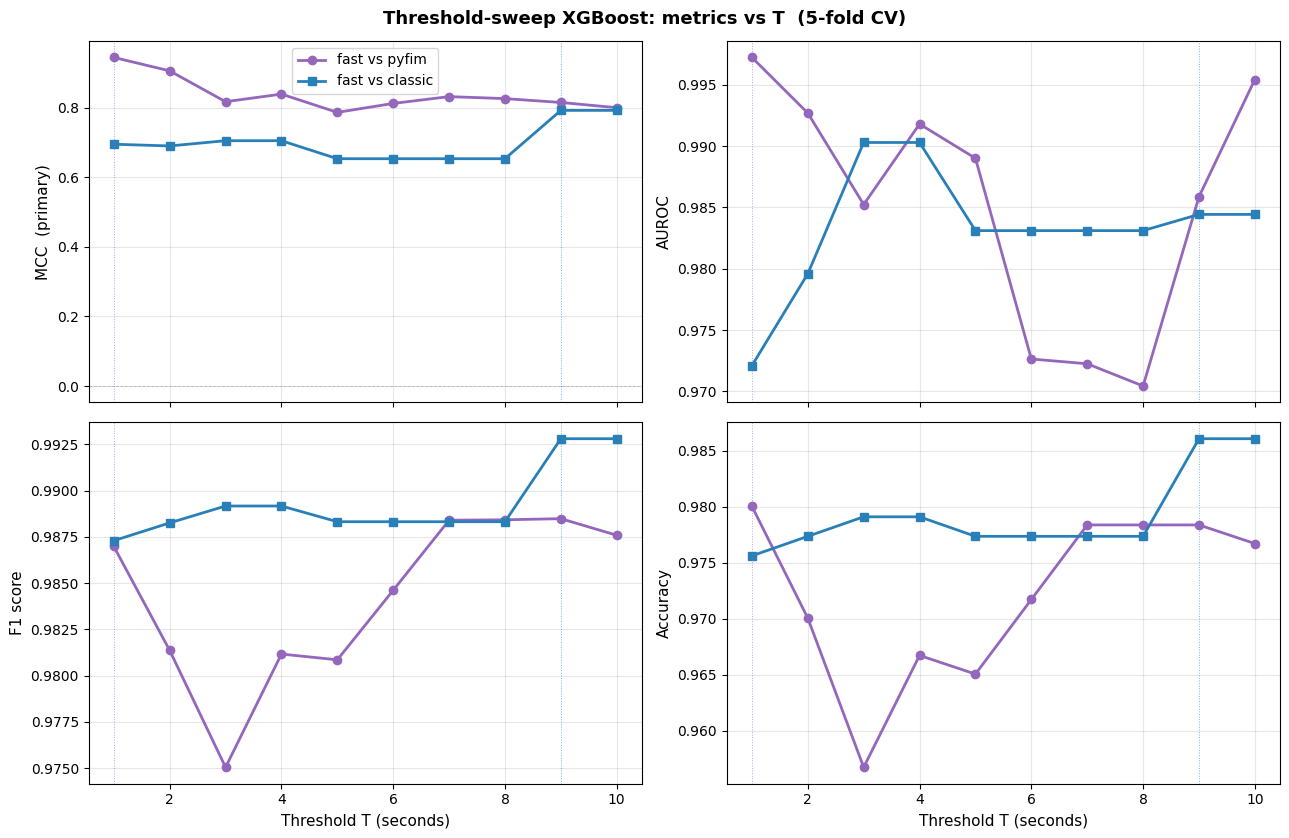

Saved threshold_sweep_combined.csv

Best T per model (by MCC):
  fast_vs_pyfim   : T =  1s   MCC = 0.944
  fast_vs_classic : T =  9s   MCC = 0.792


In [16]:
# --- Plot: metrics vs threshold T, both models side-by-side ---
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
metric_panels = [
    (axes[0, 0], "mcc",      "MCC  (primary)"),
    (axes[0, 1], "auroc",    "AUROC"),
    (axes[1, 0], "f1_score", "F1 score"),
    (axes[1, 1], "accuracy", "Accuracy"),
]
fast_color  = STYLE["fastapriori_fast"][0]
pyfim_color = STYLE["pyfim (best)"][0]
classic_color = STYLE.get("fastapriori_classic", ("#3498db",))[0]

for ax, col, title in metric_panels:
    ax.plot(sweep_fp["threshold_s"], sweep_fp[col], "-o",
            color=pyfim_color, lw=2, ms=6, label="fast vs pyfim")
    ax.plot(sweep_fc["threshold_s"], sweep_fc[col], "-s",
            color=classic_color, lw=2, ms=6, label="fast vs classic")
    ax.axvline(best_fp["T"], color=pyfim_color, lw=0.7, ls=":", alpha=0.6)
    ax.axvline(best_fc["T"], color=classic_color, lw=0.7, ls=":", alpha=0.6)
    ax.set_ylabel(title, fontsize=11)
    ax.grid(True, alpha=0.3)
    if col == "mcc":
        ax.axhline(0, color="#888888", lw=0.6, ls="--", alpha=0.5)

for ax in axes[1, :]:
    ax.set_xlabel("Threshold T (seconds)", fontsize=11)
axes[0, 0].legend(loc="best", fontsize=10, frameon=True)

fig.suptitle("Threshold-sweep XGBoost: metrics vs T  (5-fold CV)",
             fontsize=13, fontweight="bold")
fig.tight_layout()

out = OUT_DIR / f"ml_threshold_sweep_metrics_{TS}.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

# combined sweep table
combined = pd.concat([sweep_fp, sweep_fc], ignore_index=True)
combined.to_csv(ML_OUT / "threshold_sweep_combined.csv", index=False)
print("Saved threshold_sweep_combined.csv")
print()
print("Best T per model (by MCC):")
print(f"  fast_vs_pyfim   : T = {best_fp['T']:2d}s   MCC = {best_fp['mcc']:.3f}")
print(f"  fast_vs_classic : T = {best_fc['T']:2d}s   MCC = {best_fc['mcc']:.3f}")

## Best-T models and feature importance

=== fast vs pyfim_best   ·   T* = 1s   ·   MCC = 0.944 ===

                                     precision    recall  f1-score   support

        recommend pyfim (saves >1s)       0.96      0.95      0.96       141
recommend fast (or pyfim saves <1s)       0.98      0.99      0.99       460

                           accuracy                           0.98       601
                          macro avg       0.97      0.97      0.97       601
                       weighted avg       0.98      0.98      0.98       601



Saved <artifacts>\results\derived\ml_campaign_2026-05\ml_best_fast_vs_pyfim_T_v11_20260523_115442.png


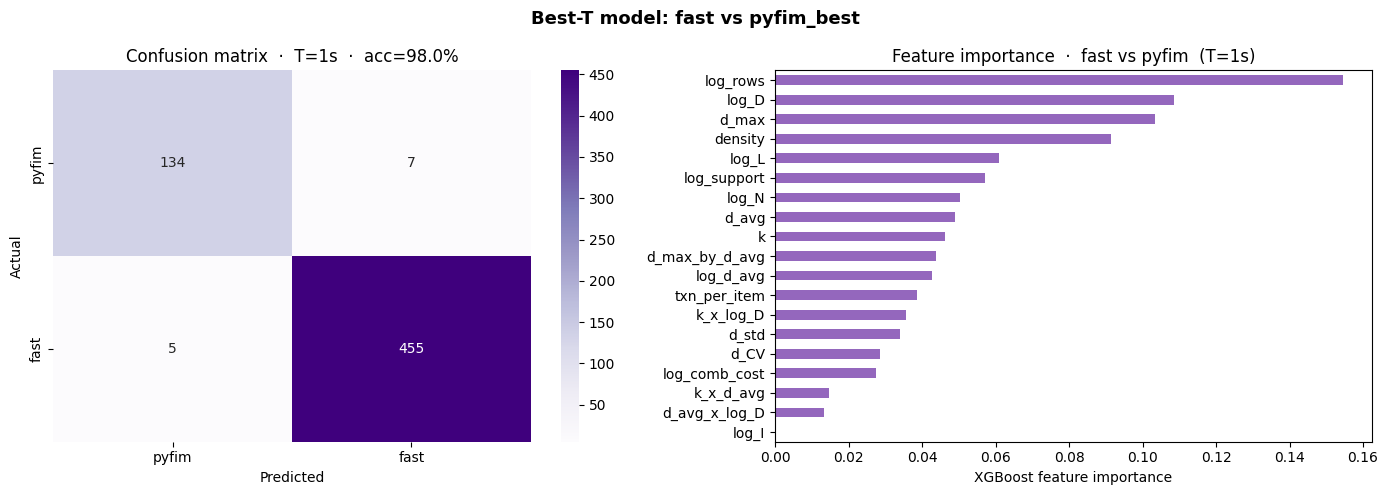

Saved winner_model_fast_vs_pyfim_T_v11.pkl

Misclassified configs (12):
                dataset  k  min_support  fast_time  pyfim_time  time_saved  pred actual
T25.I8.D5000k.N40k.L40k  2       0.0010  16.583156   12.178547   -4.404610  fast  pyfim
     T12.I4.D5k.N1k.L1k  3       0.0001   4.498667    0.410179   -4.088488  fast  pyfim
T30.I8.D2000k.N10k.L10k  2       0.0100   6.334836    2.725306   -3.609530  fast  pyfim
    T30.I8.D50k.N5k.L5k  3       0.0001   3.670222    0.842934   -2.827288  fast  pyfim
             Chainstore  9       0.0001   2.729329    1.445137   -1.284192  fast  pyfim
              Instacart  3       0.0005   7.492099    6.296583   -1.195516  fast  pyfim
              Instacart  3       0.0100   4.370620    3.212714   -1.157906  fast  pyfim
                Kosarak  3       0.0100   1.590459    0.672511   -0.917947 pyfim   fast
             Chainstore  5       0.0001   2.550545    1.683071   -0.867474 pyfim   fast
              Instacart  3       0.0010   6.2206

In [17]:
# --- Best-T model details: fast vs pyfim ---
import seaborn as sns
import pickle

T_star = best_fp["T"]
y_true = best_fp["y"]; y_pred = best_fp["y_pred"]; y_prob = best_fp["y_prob"]
X_full = best_fp["X"]; table = best_fp["table"]

print(f"=== fast vs pyfim_best   ·   T* = {T_star}s   ·   "
      f"MCC = {best_fp['mcc']:.3f} ===")
print()
print(classification_report(
    y_true, y_pred,
    target_names=[f"recommend pyfim (saves >{T_star}s)",
                  f"recommend fast (or pyfim saves <{T_star}s)"],
    zero_division=0,
))

# Refit on full data for final feature importance + saved model
clf_final = xgb.XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, eval_metric="logloss",
)
clf_final.fit(X_full, y_true)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Confusion matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["pyfim", "fast"],
            yticklabels=["pyfim", "fast"], ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Confusion matrix  ·  T={T_star}s  ·  "
                  f"acc={accuracy_score(y_true, y_pred):.1%}")

# (b) Feature importance
imp = (pd.Series(clf_final.feature_importances_, index=FEATURES)
         .sort_values(ascending=True))
imp.plot.barh(ax=axes[1], color=STYLE["pyfim (best)"][0])
axes[1].set_xlabel("XGBoost feature importance")
axes[1].set_title(f"Feature importance  ·  fast vs pyfim  (T={T_star}s)")

fig.suptitle("Best-T model: fast vs pyfim_best", fontsize=13, fontweight="bold")
fig.tight_layout()
out = OUT_DIR / f"ml_best_fast_vs_pyfim_T_v1{T_star}_{TS}.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

# Save the model
with open(ML_OUT / f"winner_model_fast_vs_pyfim_T{T_star}.pkl", "wb") as f:
    pickle.dump({
        "classifier": clf_final, "features": FEATURES,
        "threshold_seconds": T_star, "mcc": best_fp["mcc"],
        "accuracy": accuracy_score(y_true, y_pred),
        "n_train": len(X_full),
        "description": f"Recommend fast unless pyfim_best saves >{T_star}s",
    }, f)
print(f"Saved winner_model_fast_vs_pyfim_T_v1{T_star}.pkl")

# Show the configs the model gets wrong
wrong = (y_pred != y_true)
if wrong.any():
    err = table.loc[wrong, ["dataset", "k", "min_support",
                            "fast_time", "pyfim_time", "time_saved"]].copy()
    err["pred"] = ["fast" if p == 1 else "pyfim" for p in y_pred[wrong]]
    err["actual"] = ["fast" if a == 1 else "pyfim" for a in y_true[wrong]]
    err = err.sort_values("time_saved")
    print(f"\nMisclassified configs ({len(err)}):")
    print(err.to_string(index=False))

imp_pyfim = imp.copy()  # save for the comparison cell below

=== fast vs classic   ·   T* = 9s   ·   MCC = 0.792 ===

                                       precision    recall  f1-score   support

        recommend classic (saves >9s)       1.00      0.64      0.78        22
recommend fast (or classic saves <9s)       0.99      1.00      0.99       552

                             accuracy                           0.99       574
                            macro avg       0.99      0.82      0.89       574
                         weighted avg       0.99      0.99      0.98       574



Saved <artifacts>\results\derived\ml_campaign_2026-05\ml_best_fast_vs_classic_T_v19_20260523_115442.png


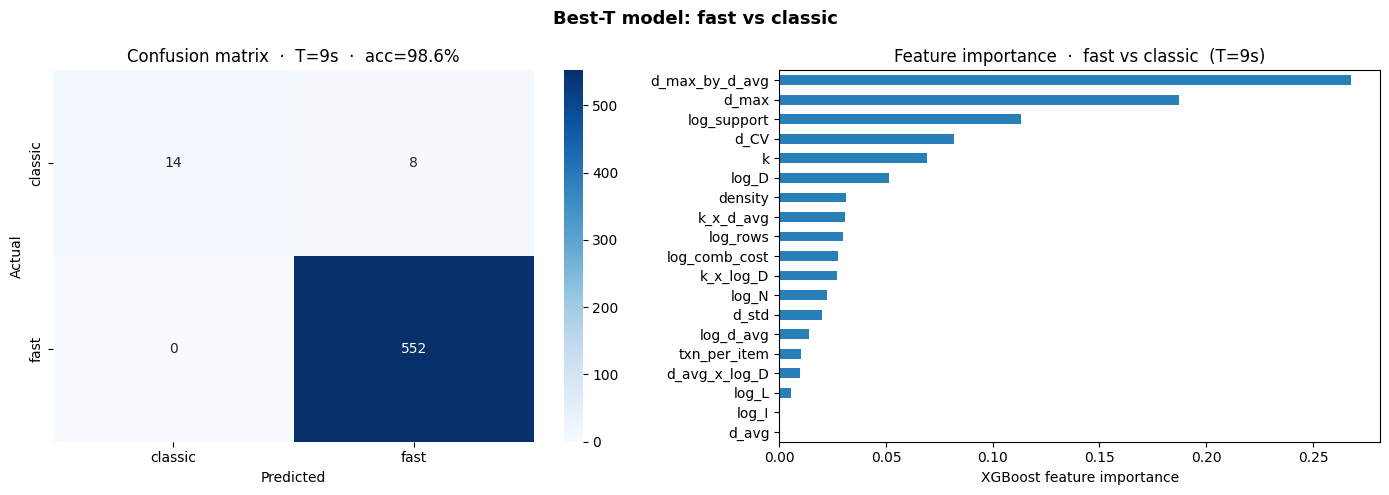

Saved winner_model_fast_vs_classic_T9.pkl

Misclassified configs (8):
           dataset  k  min_support   fast_time  classic_time   time_saved pred  actual
     Online Retail  4       0.0005 1500.000000    500.000000 -1000.000000 fast classic
     Online Retail  9       0.0010 1500.000000    500.000000 -1000.000000 fast classic
     Online Retail  8       0.0010 1500.000000    500.000000 -1000.000000 fast classic
     Online Retail  7       0.0010 1500.000000    500.000000 -1000.000000 fast classic
           Kosarak  5       0.0005 1500.000000    589.638973  -910.361027 fast classic
     Online Retail  6       0.0010  168.231314    125.757301   -42.474013 fast classic
T12.I4.D5k.N1k.L1k  5       0.0001   92.021383     53.577409   -38.443974 fast classic
         Groceries  6       0.0001  104.094054     68.643121   -35.450933 fast classic


In [18]:
# --- Best-T model details: fast vs classic ---
T_star = best_fc["T"]
y_true = best_fc["y"]; y_pred = best_fc["y_pred"]; y_prob = best_fc["y_prob"]
X_full = best_fc["X"]; table = best_fc["table"]

print(f"=== fast vs classic   ·   T* = {T_star}s   ·   "
      f"MCC = {best_fc['mcc']:.3f} ===")
print()
print(classification_report(
    y_true, y_pred,
    target_names=[f"recommend classic (saves >{T_star}s)",
                  f"recommend fast (or classic saves <{T_star}s)"],
    zero_division=0,
))

clf_final = xgb.XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, eval_metric="logloss",
)
clf_final.fit(X_full, y_true)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_true, y_pred)
classic_color = STYLE.get("fastapriori_classic", ("#3498db",))[0]
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["classic", "fast"],
            yticklabels=["classic", "fast"], ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Confusion matrix  ·  T={T_star}s  ·  "
                  f"acc={accuracy_score(y_true, y_pred):.1%}")

imp = (pd.Series(clf_final.feature_importances_, index=FEATURES)
         .sort_values(ascending=True))
imp.plot.barh(ax=axes[1], color=classic_color)
axes[1].set_xlabel("XGBoost feature importance")
axes[1].set_title(f"Feature importance  ·  fast vs classic  (T={T_star}s)")

fig.suptitle("Best-T model: fast vs classic", fontsize=13, fontweight="bold")
fig.tight_layout()
out = OUT_DIR / f"ml_best_fast_vs_classic_T_v1{T_star}_{TS}.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

with open(ML_OUT / f"winner_model_fast_vs_classic_T{T_star}.pkl", "wb") as f:
    pickle.dump({
        "classifier": clf_final, "features": FEATURES,
        "threshold_seconds": T_star, "mcc": best_fc["mcc"],
        "accuracy": accuracy_score(y_true, y_pred),
        "n_train": len(X_full),
        "description": f"Recommend fast unless classic saves >{T_star}s",
    }, f)
print(f"Saved winner_model_fast_vs_classic_T{T_star}.pkl")

wrong = (y_pred != y_true)
if wrong.any():
    err = table.loc[wrong, ["dataset", "k", "min_support",
                            "fast_time", "classic_time", "time_saved"]].copy()
    err["pred"] = ["fast" if p == 1 else "classic" for p in y_pred[wrong]]
    err["actual"] = ["fast" if a == 1 else "classic" for a in y_true[wrong]]
    err = err.sort_values("time_saved")
    print(f"\nMisclassified configs ({len(err)}):")
    print(err.to_string(index=False))

imp_classic = imp.copy()  # save for the comparison cell below

## Leave-one-dataset-out validation

In [19]:
# --- Leave-one-dataset-out (LOGO) validation ---
# Stratified 5-fold CV can place configs from the same dataset in both train
# and test folds, leaking dataset-level signal. LOGO holds out each
# dataset's configs as a single test fold.
#
# Aggregation nuance: many held-out folds are SINGLE-CLASS (e.g. fast wins
# every config in that dataset at the chosen T*), which makes per-fold MCC
# undefined. We therefore report three aggregations:
#   1. Pooled (all 18 folds): concatenate all predictions, compute MCC.
#      Strict but heavily skewed when most folds are single-class.
#   2. Macro over evaluable folds: mean per-fold MCC across the folds where
#      both classes are present in the test set.
#   3. Pooled over evaluable folds: pool predictions only from datasets
#      whose held-out fold has both classes; compute MCC on that pool.
# AUROC is well-defined as long as the *combined* set has both classes,
# so it is much less sensitive to single-class folds than MCC.

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (matthews_corrcoef, f1_score, roc_auc_score,
                             accuracy_score)
import xgboost as xgb

def logo_evaluate(table, fast_col, baseline_col, features, T_star, label, seed=42):
    work = table.copy()
    work["time_saved"] = work[baseline_col] - work[fast_col]
    y = (work["time_saved"] > -T_star).astype(int).values
    X = work[features].values
    groups = work["dataset"].values

    logo = LeaveOneGroupOut()
    y_pred_all = np.zeros(len(y), dtype=int)
    y_prob_all = np.zeros(len(y), dtype=float)
    fold_rows = []
    for tr, te in logo.split(X, y, groups=groups):
        ds = groups[te][0]
        if len(set(y[tr])) < 2:
            y_pred_all[te] = int(round(y[tr].mean()))
            y_prob_all[te] = float(y[tr].mean())
        else:
            clf = xgb.XGBClassifier(
                n_estimators=300, max_depth=6, learning_rate=0.1,
                subsample=0.8, colsample_bytree=0.8,
                random_state=seed, n_jobs=-1, eval_metric="logloss",
            )
            clf.fit(X[tr], y[tr])
            y_pred_all[te] = clf.predict(X[te])
            y_prob_all[te] = clf.predict_proba(X[te])[:, 1]
        both = (len(set(y[te])) == 2)
        fold_rows.append({
            "dataset": ds, "n_test": len(te), "both_classes": both,
            "mcc":   matthews_corrcoef(y[te], y_pred_all[te]) if both else np.nan,
            "auroc": roc_auc_score(y[te], y_prob_all[te])     if both else np.nan,
            "f1":    f1_score(y[te], y_pred_all[te], zero_division=0),
            "acc":   accuracy_score(y[te], y_pred_all[te]),
        })

    fr = pd.DataFrame(fold_rows)
    eval_mask = fr["both_classes"]
    n_eval = int(eval_mask.sum()); n_skip = int((~eval_mask).sum())

    # Pool predictions only from evaluable folds (datasets with both classes).
    eval_groups = set(fr.loc[eval_mask, "dataset"].values)
    em = np.array([g in eval_groups for g in groups])
    ev = (em.sum() > 0 and len(set(y[em])) == 2)

    return {
        "label": label, "T_star": T_star, "n": len(y),
        "n_eval_folds": n_eval, "n_skip_folds": n_skip,
        "pooled_mcc":   matthews_corrcoef(y, y_pred_all),
        "pooled_auroc": roc_auc_score(y, y_prob_all),
        "pooled_f1":    f1_score(y, y_pred_all, zero_division=0),
        "pooled_acc":   accuracy_score(y, y_pred_all),
        "macro_mcc":    fr.loc[eval_mask, "mcc"].mean()   if n_eval else np.nan,
        "macro_auroc":  fr.loc[eval_mask, "auroc"].mean() if n_eval else np.nan,
        "pe_mcc":       matthews_corrcoef(y[em], y_pred_all[em]) if ev else np.nan,
        "pe_auroc":     roc_auc_score(y[em], y_prob_all[em])     if ev else np.nan,
        "pe_f1":        f1_score(y[em], y_pred_all[em], zero_division=0) if em.sum() else np.nan,
        "pe_acc":       accuracy_score(y[em], y_pred_all[em])    if em.sum() else np.nan,
        "fold_table":   fr,
    }

print("=== Leave-one-dataset-out (LOGO) cross-validation ===")
logo_fp = logo_evaluate(df_fp, "fast_time", "pyfim_time",
                        FEATURES, T_star=best_fp["T"],
                        label="fast_vs_pyfim_median")
logo_fc = logo_evaluate(df_fc, "fast_time", "classic_time",
                        FEATURES, T_star=best_fc["T"],
                        label="fast_vs_classic")

def _row(r):
    return {"n_total": r["n"], "n_eval_folds": r["n_eval_folds"],
            "pooled_mcc": r["pooled_mcc"], "pooled_auroc": r["pooled_auroc"],
            "macro_mcc":  r["macro_mcc"],  "macro_auroc":  r["macro_auroc"],
            "pe_mcc":     r["pe_mcc"],     "pe_auroc":     r["pe_auroc"]}

summary = pd.DataFrame({
    "fast_vs_pyfim_median": _row(logo_fp),
    "fast_vs_classic":      _row(logo_fc),
}).T
print(summary.to_string(float_format="%.3f"))

# Save full per-fold breakdown + summary
out = OUT_DIR / f"logo_validation_{TS}.csv"
summary.to_csv(out, float_format="%.6f")
print(f"Saved {out}")

print("=== Per-fold breakdown (fast vs pyfim) ===")
print(logo_fp["fold_table"].to_string(index=False, float_format="%.3f"))
print("=== Per-fold breakdown (fast vs classic) ===")
print(logo_fc["fold_table"].to_string(index=False, float_format="%.3f"))

=== Leave-one-dataset-out (LOGO) cross-validation ===


                      n_total  n_eval_folds  pooled_mcc  pooled_auroc  macro_mcc  macro_auroc  pe_mcc  pe_auroc
fast_vs_pyfim_median  601.000        13.000       0.153         0.762      0.311        0.882   0.214     0.810
fast_vs_classic       574.000         5.000       0.000         0.913      0.000        0.941   0.000     0.896
Saved <artifacts>\results\derived\ml_campaign_2026-05\logo_validation_20260523_115442.csv
=== Per-fold breakdown (fast vs pyfim) ===
                 dataset  n_test  both_classes   mcc  auroc    f1   acc
           BMS-WebView-1      31          True 0.000  1.000 0.931 0.871
           BMS-WebView-2      39          True 0.000  1.000 0.917 0.846
              Chainstore      39          True 0.185  0.936 0.409 0.333
               Groceries      39          True 0.000  1.000 0.917 0.846
               Instacart      39          True 0.000  0.955 0.304 0.179
                 Kosarak      30          True 0.276  0.958 0.414 0.433
           Online Retail   

## Feature-importance table and the 1×3 paper figure

Saved <artifacts>\results\derived\ml_campaign_2026-05\ml_feature_importance_compare_20260523_115442.png


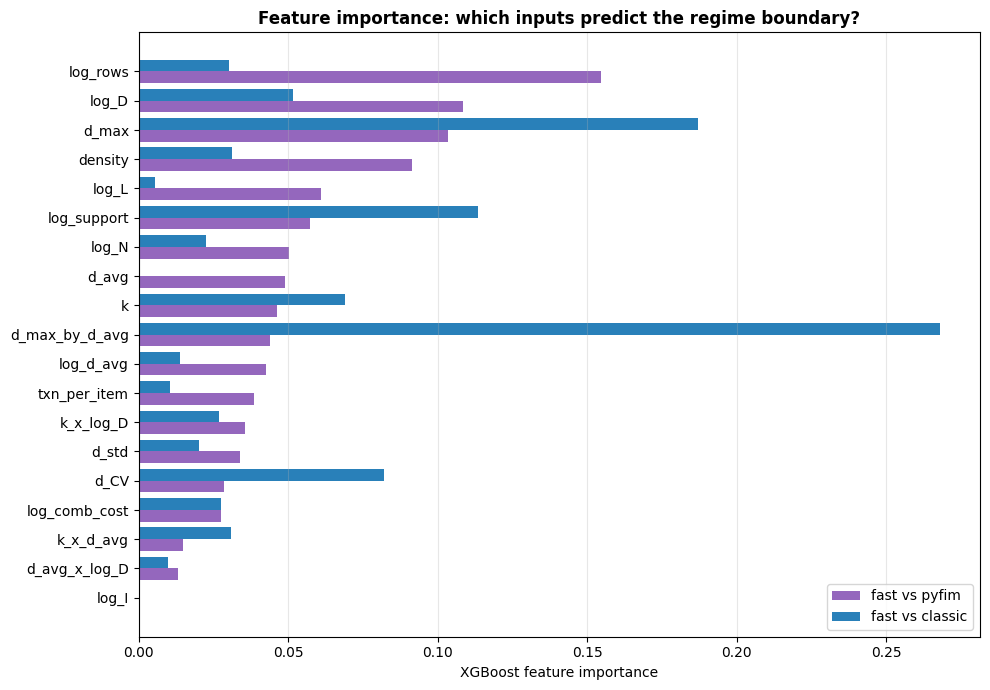


SUMMARY  ·  threshold-sweep XGBoost models
  fast vs pyfim   :  best T =  1s   MCC = 0.944   acc = 98.0%   (n = 601)
  fast vs classic :  best T =  9s   MCC = 0.792   acc = 98.6%   (n = 574)

Top 5 features (combined importance):
                fast vs pyfim  fast vs classic  combined
d_max_by_d_avg       0.043888         0.267962  0.311849
d_max                0.103286         0.187102  0.290388
log_rows             0.154676         0.030111  0.184787
log_support          0.057149         0.113322  0.170471
log_D                0.108485         0.051457  0.159942


In [20]:
# --- Side-by-side: which features predict each regime boundary? ---
imp_table = pd.DataFrame({
    "fast vs pyfim":   imp_pyfim,
    "fast vs classic": imp_classic,
}).fillna(0).sort_values("fast vs pyfim", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
y_pos = np.arange(len(imp_table))
bar_h = 0.4
ax.barh(y_pos - bar_h/2, imp_table["fast vs pyfim"], height=bar_h,
        color=STYLE["pyfim (best)"][0], label="fast vs pyfim")
ax.barh(y_pos + bar_h/2, imp_table["fast vs classic"], height=bar_h,
        color=STYLE.get("fastapriori_classic", ("#3498db",))[0],
        label="fast vs classic")
ax.set_yticks(y_pos)
ax.set_yticklabels(imp_table.index)
ax.set_xlabel("XGBoost feature importance")
ax.set_title("Feature importance: which inputs predict the regime boundary?",
             fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()

out = OUT_DIR / f"ml_feature_importance_compare_{TS}.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

print()
print("=" * 78)
print("SUMMARY  ·  threshold-sweep XGBoost models")
print("=" * 78)
print(f"  fast vs pyfim   :  best T = {best_fp['T']:2d}s   "
      f"MCC = {best_fp['mcc']:.3f}   "
      f"acc = {(best_fp['y_pred'] == best_fp['y']).mean():.1%}   "
      f"(n = {len(best_fp['y'])})")
print(f"  fast vs classic :  best T = {best_fc['T']:2d}s   "
      f"MCC = {best_fc['mcc']:.3f}   "
      f"acc = {(best_fc['y_pred'] == best_fc['y']).mean():.1%}   "
      f"(n = {len(best_fc['y'])})")
print()
print("Top 5 features (combined importance):")
imp_table["combined"] = imp_table.sum(axis=1)
print(imp_table.sort_values("combined", ascending=False).head(5).to_string())

Saved <artifacts>\results\derived\ml_campaign_2026-05\ml_sweep_and_importance_1x3_20260523_115442.png


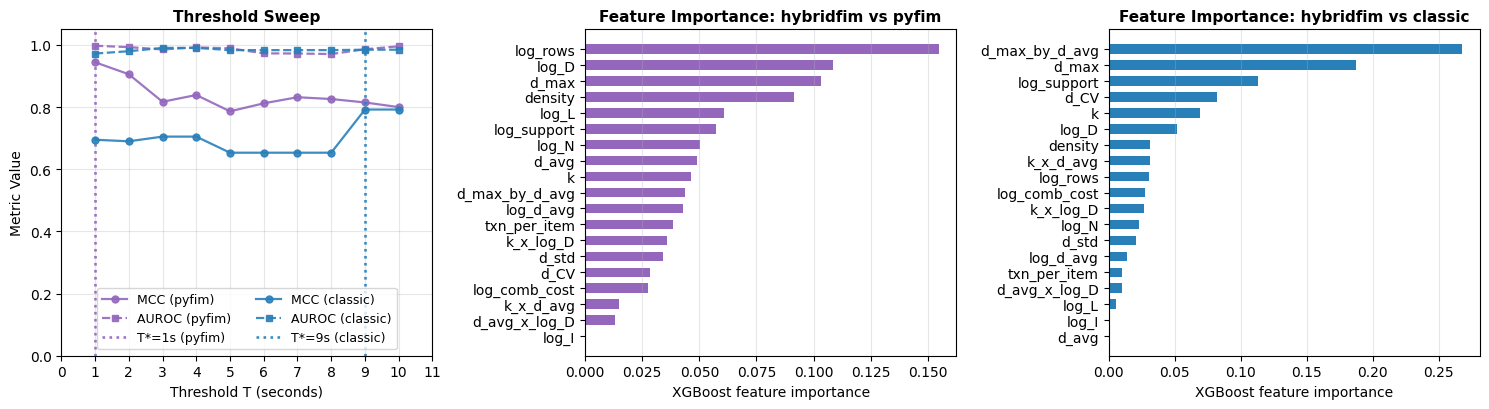

In [21]:
# --- 1x3 ML figure: combined threshold sweep + feature importance pair ---
# Replaces the 2x2 grid for the paper. Same aesthetic; just
# horizontally laid out and with the threshold panels merged (MCC + AUROC
# only; F1/accuracy dropped per author preference).
from matplotlib.ticker import FixedLocator

_pyfim_color   = STYLE["pyfim (best)"][0]
_classic_color = STYLE.get("fastapriori_classic", ("#3498db",))[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# -- Panel 0: combined threshold sweep ----------------------------------
ax = axes[0]
# Each entry: (sweep_df, best_dict, color, classifier_label_for_legend)
_sweep_specs = [
    (sweep_fp, best_fp, _pyfim_color,   "(pyfim)"),
    (sweep_fc, best_fc, _classic_color, "(classic)"),
]
for sweep, best, color, clf_label in _sweep_specs:
    ax.plot(sweep["threshold_s"], sweep["mcc"],
            linestyle="-",  marker="o", lw=1.6, ms=5, color=color,
            alpha=0.9, label=f"MCC {clf_label}")
    ax.plot(sweep["threshold_s"], sweep["auroc"],
            linestyle="--", marker="s", lw=1.6, ms=5, color=color,
            alpha=0.9, label=f"AUROC {clf_label}")
    ax.axvline(best["T"], color=color, lw=1.9, ls=":", alpha=0.9,
               label=f"T*={best['T']}s {clf_label}")

ax.set_xlabel("Threshold T (seconds)", fontsize=10)
ax.set_ylabel("Metric Value", fontsize=10)
xmin, xmax = 0, 10.5
ax.set_xlim(xmin, xmax)
ax.set_xticks(np.arange(xmin, xmax + 1, 1))
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_locator(FixedLocator([0.0, 0.2, 0.4, 0.6, 0.8, 1.0]))
ax.set_title("Threshold Sweep",
             fontsize=11, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower center", fontsize=9, ncol=2, frameon=True)

# -- Panel 1: hybridfim vs pyfim feature importance --------------------
ip = imp_pyfim.sort_values(ascending=True)
axes[1].barh(np.arange(len(ip)), ip.values, color=_pyfim_color, height=0.6)
axes[1].set_yticks(np.arange(len(ip)))
axes[1].set_yticklabels(ip.index, fontsize=10)
axes[1].set_xlabel("XGBoost feature importance", fontsize=10)
axes[1].set_title("Feature Importance: hybridfim vs pyfim",
                  fontsize=11, fontweight="bold")
axes[1].grid(True, axis="x", alpha=0.3)

# -- Panel 2: hybridfim vs classic feature importance ------------------
ic = imp_classic.sort_values(ascending=True)
axes[2].barh(np.arange(len(ic)), ic.values, color=_classic_color, height=0.6)
axes[2].set_yticks(np.arange(len(ic)))
axes[2].set_yticklabels(ic.index, fontsize=10)
axes[2].set_xlabel("XGBoost feature importance", fontsize=10)
axes[2].set_title("Feature Importance: hybridfim vs classic",
                  fontsize=11, fontweight="bold")
axes[2].grid(True, axis="x", alpha=0.3)

fig.tight_layout()
out = OUT_DIR / f"ml_sweep_and_importance_1x3_{TS}.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## Regime figure
**Correction.** The May 2026 analysis hard-coded the win-rate badges (`PANEL_WIN_PCT`). The k=2 values
match the data; the k≥3 values (24.6%, 89.7%) cannot be reproduced from it. The next cell computes them
with the definition stated there and shows both; the figure uses the computed values.

In [22]:
# compute the badges with the definition of the May 2026 analysis:
# % of (dataset, k) cells at each dataset's lowest support where HybridFIM (8T) is faster;
# pyfim panels compare with the median of the three PyFIM variants (as the panels do), using
# successful measurements only (no imputed failures).
HARD_CODED = {("k=2", "pyfim"): "94.4%", ("k=2", "classic"): "100%",
              ("kge3", "pyfim"): "24.6%", ("kge3", "classic"): "89.7%"}
_ok = agg[agg.wall_s_n_ok > 0]
_low = _ok[_ok.min_support == _ok.dataset.map(_ok.groupby("dataset").min_support.min())]
_W = _low.pivot_table(index=["dataset", "k"], columns="method", values="wall_s_median")
_pyfim_med = _W[["pyfim_apriori", "pyfim_eclat", "pyfim_fpgrowth"]].median(axis=1)
PANEL_WIN_PCT_COMPUTED, rows_ = {}, []
for kk, sel in [("k=2", _W.index.get_level_values("k") == 2), ("kge3", _W.index.get_level_values("k") >= 3)]:
    for comp, b in [("pyfim", _pyfim_med), ("classic", _W["fastapriori_classic"])]:
        f_, b_ = _W["fastapriori_fast"][sel], b[sel]
        v = f_.notna() & b_.notna()
        pct = (f_[v] < b_[v]).mean()
        PANEL_WIN_PCT_COMPUTED[(kk, comp)] = f"{pct:.1%}"
        rows_.append(dict(panel=f"{kk} vs {comp}", hard_coded=HARD_CODED[(kk, comp)],
                          computed=f"{pct:.1%}", wins=int((f_[v] < b_[v]).sum()), cells=int(v.sum())))
pd.DataFrame(rows_)

,panel,hard_coded,computed,wins,cells
0,k=2 vs pyfim,94.4%,94.4%,17,18
1,k=2 vs classic,100%,100.0%,17,17
2,kge3 vs pyfim,24.6%,31.3%,31,99
3,kge3 vs classic,89.7%,91.2%,83,91


Saved <artifacts>\results\derived\ml_campaign_2026-05\regime_scatter_density_dmax_labels_cbrt_all_shaded_custom_t25_bubble_01_hybrid_20260522_003913.png


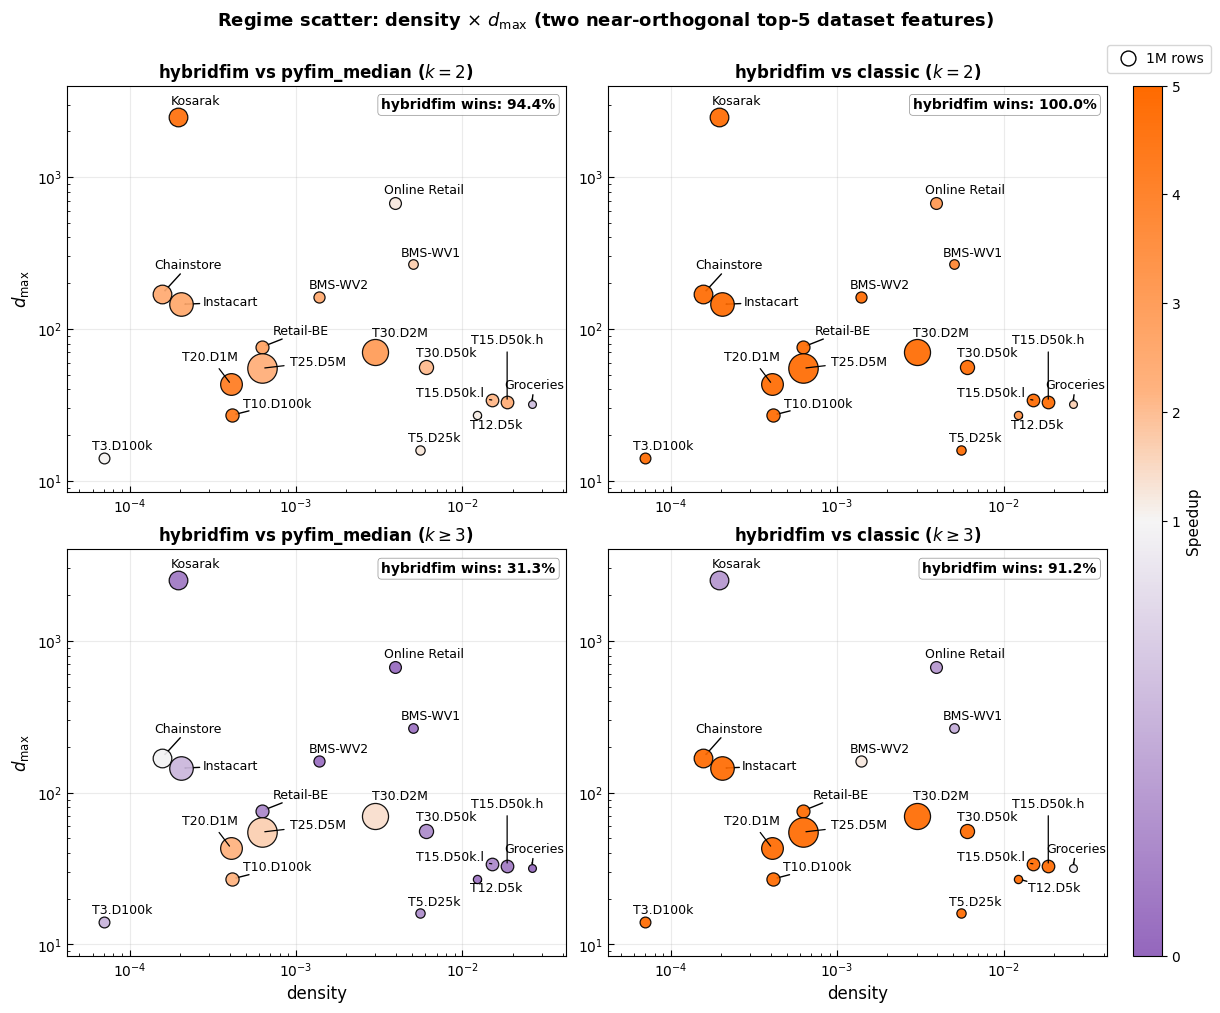

In [23]:
# --- ML-derived regime scatter on two near-orthogonal top-5 features ---
# 2x2 grid: rows split k=2 from k>=3 (because density and d_max are
# dataset-level features and don't change with k, so all k-points for a
# given dataset overlap at the same (x,y)). Columns = baseline (pyfim, classic).
#
#   X = log10(density)              -- canonical regime axis (sparse <-> dense)
#   Y = log10(d_max)                -- worst-case basket width (tail statistic)
#
# Both are top-5 XGBoost features; algebraically d_max does not appear in
# density's formula (= d_avg / m), and empirically r(log_d_max, log_density)
# ~= -0.25 on this suite, so they carry near-independent information.
#
# Encoding:
#   color  = log10(speedup), neon-orange (wins) <-> deep-purple (loses)
#   shape  = real (circle) vs synthetic (square)
# For the k>=3 row, speedup is the median across k in {3,4,5,...} per dataset
# at the lowest-support cell (one point per dataset, matching the k=2 row).

from matplotlib.lines import Line2D
from adjustText import adjust_text
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
import matplotlib

_SYNTH_PREFIX = ("T3.", "T5.", "T10.", "T12.", "T15.", "T20.", "T25.", "T30.")
SHAPE_COLS = ["density", "d_max", "d_avg", "n_transactions", "n_items", "n_rows"]

def _lowest_per_dsk(table, fast_col, baseline_col):
    """One row per (dataset, k) at the lowest support cell, with speedup."""
    work = table.copy()
    work["speedup"] = work[baseline_col] / work[fast_col]
    rows = []
    for _, grp in work.groupby(["dataset", "k"]):
        if len(grp):
            rows.append(grp.loc[grp["min_support"].idxmin()])
    return pd.DataFrame(rows)

def _agg_per_dataset(low_tab, k_filter):
    """Collapse to one row per dataset over the chosen k filter (median speedup)."""
    sub = low_tab[k_filter(low_tab["k"])].copy()
    if sub.empty:
        return sub
    out = (sub.groupby("dataset")
              .agg(speedup=("speedup", "median"),
                   **{c: (c, "first") for c in SHAPE_COLS})
              .reset_index())
    out["is_synth"] = out["dataset"].str.startswith(_SYNTH_PREFIX)
    return out

# IMPORTANT: df_fp upstream uses pyfim_BEST (min across pyfim_apriori/
# fpgrowth/eclat) because that is the right baseline for the XGBoost
# regime classifier (strongest pyfim variant). For this figure, however,
# the panel title and the section 6.4 narrative compare against
# pyfim_MEDIAN (the practitioner-selection baseline used throughout
# section 5). We override pyfim_time locally here without touching df_fp.
_pyfim_median = (df[df["method"].str.startswith("pyfim_")]
                 .groupby(["dataset", "k", "min_support"])["wall_s_median"]
                 .median().rename("pyfim_time").reset_index())
_df_fp_med = (df_fp.drop(columns=["pyfim_time"])
              .merge(_pyfim_median, on=["dataset", "k", "min_support"],
                     how="inner"))

low_fp = _lowest_per_dsk(_df_fp_med, "fast_time", "pyfim_time")
low_fc = _lowest_per_dsk(df_fc, "fast_time", "classic_time")

panels_data = {
    ("k=2",   "pyfim"):   _agg_per_dataset(low_fp, lambda k: k == 2),
    ("k=2",   "classic"): _agg_per_dataset(low_fc, lambda k: k == 2),
    ("kge3",  "pyfim"):   _agg_per_dataset(low_fp, lambda k: k >= 3),
    ("kge3",  "classic"): _agg_per_dataset(low_fc, lambda k: k >= 3),
}

# Custom diverging colormap: deep purple (loses) -> off-white (parity) -> neon orange (wins)
NEON_ORANGE = "#ff6a00"
TAB_PURPLE  = "#9467bd"   # matches pyfim hue (tab:purple)
cmap = LinearSegmentedColormap.from_list(
    "neon_orange_purple",
    [(0.00, TAB_PURPLE),
     (0.50, "#f5f5f5"),
     (0.65, "#ffb380"),   # pale orange at speedup ~2.3
     (1.00, NEON_ORANGE)],
    N=256,
)

# Shared symmetric log-speedup norm across all four panels
# Linear speedup scale, capped at 5 (anything faster saturates to neon orange,
# anything below 1 fades toward purple).
norm = TwoSlopeNorm(vmin=0.0, vcenter=1.0, vmax=5.0)

# Compute global x/y limits with padding so every dataset (incl. Kosarak) fits
all_density = pd.concat([d["density"] for d in panels_data.values()])
all_dmax    = pd.concat([d["d_max"]   for d in panels_data.values()])
xlim = (all_density.min() * 0.6, all_density.max() * 1.6)
ylim = (all_dmax.min()    * 0.6, all_dmax.max()    * 1.6)

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5),
                         sharex=True, sharey=True,
                         constrained_layout=True)

LAYOUT = [
    ((0, 0), ("k=2",  "pyfim"),   "hybridfim vs pyfim_median ($k=2$)"),
    ((0, 1), ("k=2",  "classic"), "hybridfim vs classic ($k=2$)"),
    ((1, 0), ("kge3", "pyfim"),   "hybridfim vs pyfim_median ($k \\geq 3$)"),
    ((1, 1), ("kge3", "classic"), "hybridfim vs classic ($k \\geq 3$)"),
]

# Short labels for the four named real datasets discussed in section 6.4
LABEL_ALL = {
    # Real datasets
    "Groceries":                 "Groceries",
    "BMS-WebView-1":             "BMS-WV1",
    "BMS-WebView-2":             "BMS-WV2",
    "Retail (Belgian)":          "Retail-BE",
    "Online Retail":             "Online Retail",
    "Kosarak":                   "Kosarak",
    "Chainstore":                "Chainstore",
    "Instacart":                 "Instacart",
    # Synthetic datasets, T<txn-width>.D<num-transactions> [.h/.l for high/low corr]
    "T3.I2.D100k.N50k.L50k":     "T3.D100k",
    "T5.I2.D25k.N1k.L1k":        "T5.D25k",
    "T10.I4.D100k.N25k.L25k":    "T10.D100k",
    "T12.I4.D5k.N1k.L1k":        "T12.D5k",
    "T15.I8.D50k.N1k.L1k.high":  "T15.D50k.h",
    "T15.I8.D50k.N1k.L1k.low":   "T15.D50k.l",
    "T20.I4.D1000k.N50k.L50k":   "T20.D1M",
    "T25.I8.D5000k.N40k.L40k":   "T25.D5M",
    "T30.I8.D2000k.N10k.L10k":   "T30.D2M",
    "T30.I8.D50k.N5k.L5k":       "T30.D50k",
}

panel_texts = {}
panel_xy = {}
panel_static_objs = {}
for (i, j), key, panel_title in LAYOUT:
    ax = axes[i, j]
    tab = panels_data[key]
    for _, row in tab.iterrows():
        face = cmap(norm(row["speedup"]))
        ax.scatter(
            row["density"], row["d_max"],
            s=0.9*np.cbrt(row["n_rows"]),  # bubble area ~ cbrt(n_rows)
            marker="o",
            facecolor=face,
            edgecolor="black", linewidth=0.9,
            alpha=0.92, zorder=3,
        )
    # Annotate every dataset; we defer adjust_text to after layout is final.
    panel_texts[(i, j)] = []
    panel_xy[(i, j)] = ([], [])
    NO_ADJUST_DS = {
        "Online Retail", "Kosarak",
        "BMS-WebView-1", "BMS-WebView-2",
        "T3.I2.D100k.N50k.L50k",
        "T5.I2.D25k.N1k.L1k",
        "T30.I8.D2000k.N10k.L10k",
        "T30.I8.D50k.N5k.L5k",
    }
    # Manual placement with arrow: (dx_pts, dy_pts, va) relative to the bubble center
    MANUAL_OFFSET = {
        "T15.I8.D50k.N1k.L1k.high": (0,  40, "bottom"),  # above bubble
        "T15.I8.D50k.N1k.L1k.low":  (-30, 0, "bottom"),  # left of bubble
        "T25.I8.D5000k.N40k.L40k":  (40, 0, "top"),    # right + slightly down (gap to T30.D2M)
        "T20.I4.D1000k.N50k.L50k": (-15, 15, "bottom")
    }
    if not tab.empty:
        for ds_name, short in LABEL_ALL.items():
            sub = tab[tab["dataset"] == ds_name]
            if len(sub):
                row = sub.iloc[0]
                # Always register the bubble position so adjust_text avoids all bubbles
                panel_xy[(i, j)][0].append(row["density"])
                panel_xy[(i, j)][1].append(row["d_max"])
                if ds_name in MANUAL_OFFSET:
                    dx, dy, va = MANUAL_OFFSET[ds_name]
                    ann = ax.annotate(short,
                                      xy=(row["density"], row["d_max"]),
                                      xytext=(dx, dy), textcoords="offset points",
                                      fontsize=9, ha="center", va="bottom",
                                      arrowprops=dict(arrowstyle="-", color="k", lw=0.9))
                    panel_static_objs.setdefault((i, j), []).append(ann)
                elif ds_name in NO_ADJUST_DS:
                    radius_offset = np.sqrt(0.9*np.cbrt(row["n_rows"])) / 2 -2
                    ann = ax.annotate(short,
                                      xy=(row["density"], row["d_max"]),
                                      xytext=(radius_offset-10, radius_offset+2),
                                      textcoords="offset points",
                                      fontsize=9, ha="left", va="bottom")
                    panel_static_objs.setdefault((i, j), []).append(ann)
                else:
                    t = ax.text(row["density"], row["d_max"], short,
                                fontsize=9, ha="left", va="bottom")
                    panel_texts[(i, j)].append(t)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    # Tick marks on all four sides (in addition to bottom/left labels)
    ax.tick_params(axis="both", which="both",
                   top=False, right=False, bottom=True, left=True,
                   direction="in", length=4)
    ax.tick_params(axis="both", which="minor", length=2.5)
    ax.grid(True, which="major", alpha=0.25, zorder=0)
    ax.set_title(panel_title, fontsize=12, fontweight="bold")

    # Win-rate annotation per panel.
    # We display Table 3's cell-level percentages (% of (dataset,k) cells at
    # lowest support where HybridFIM wins) instead of the bubble-level rate,
    # so the text in this figure matches the table the paper reports.
    PANEL_WIN_PCT = PANEL_WIN_PCT_COMPUTED   # [bundle correction] was a hard-coded dict, see previous cell
    if len(tab):
        win_text = PANEL_WIN_PCT.get(key, f"{(tab['speedup'] >= 1).mean():.1%}")
        ax.text(0.98, 0.97, f"hybridfim wins: {win_text}",
                transform=ax.transAxes, va="top", ha="right", fontsize=10,
                fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.25",
                          facecolor="white", edgecolor="#888888",
                          alpha=0.92, linewidth=0.5))

# Force tick labels on every panel (override sharex/sharey hiding)
for ax in axes.ravel():
    ax.tick_params(axis="both", which="both",
                   labelbottom=True, labelleft=True)

# Axis labels: x on every panel (top + bottom rows), y on left column
# for ax in axes[0, :]:
#     ax.set_xlabel(r"density $= d_{\mathrm{avg}} / m$", fontsize=11)
for ax in axes[1, :]:
    ax.set_xlabel(r"density", fontsize=12)
for ax in axes[:, 0]:
    ax.set_ylabel(r"$d_{\mathrm{max}}$", fontsize=12)


# Vertical colorbar on the right, spanning both rows
sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(),
                    orientation="vertical",
                    fraction=0.04, pad=0.025, aspect=30)
cbar.set_label("Speedup",
               fontsize=11)

fig.suptitle("Regime scatter: density $\\times$ $d_{\\max}$ "
             "(two near-orthogonal top-5 dataset features)",
             fontsize=13, fontweight="bold", y=1.05)

# Run adjust_text after layout is finalized so axes sizes are stable
fig.canvas.draw()
for (i, j), texts in panel_texts.items():
    if texts:
        xs, ys = panel_xy[(i, j)]
        static_objs = panel_static_objs.get((i, j), [])
        adjust_text(texts, x=xs, y=ys, ax=axes[i, j],
                    objects=static_objs if static_objs else None,
                    arrowprops=dict(arrowstyle='->', color='k', lw=1),
                    expand=(1.4, 1.6),
                    force_text=(0.5, 0.8),
                    force_static=(1.2, 1.5),
                    time_lim=5.0)
                    #arrowprops=dict(arrowstyle="-", color="#888888", lw=0.9))
                    # expand=(1.6, 1.9),
                    # force_text=(0.4, 0.6),
                    # force_static=(0.6, 0.8),
                    # time_lim=4.0)

# Bubble-size legend: a single circle representing 1M rows
import math
s_1M = 0.9 * np.cbrt(1e6)            # scatter `s` value at 1M rows
ms_1M = 2.0 * math.sqrt(s_1M / math.pi)  # equivalent Line2D markersize
size_ref = Line2D([0], [0], marker="o", color="none",
                  markerfacecolor="white", markeredgecolor="black",
                  markersize=ms_1M, label="1M rows")
# Anchor the legend at the figure's top-right corner; constrained_layout
# leaves padding so it does not overlap the colorbar or any panel.
fig.legend(handles=[size_ref], loc="upper right",
           bbox_to_anchor=(1.01, 1.02), bbox_transform=fig.transFigure,
           frameon=True, fontsize=10,
           handletextpad=0.3, borderpad=0.5, borderaxespad=0.5)

out = OUT_DIR / f"regime_scatter_density_dmax_labels_cbrt_all_shaded_custom_t25_bubble_01_hybrid_{TS_REGIME}.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## The two paper figures, and saved vs regenerated numbers

In [24]:
import shutil
paper_pngs = [f"ml_sweep_and_importance_1x3_{TS}.png",
              f"regime_scatter_density_dmax_labels_cbrt_all_shaded_custom_t25_bubble_01_hybrid_{TS_REGIME}.png"]
for n in paper_pngs:
    print("paper figure:", rel(ML_OUT / n))

if CAMPAIGN == MAY:
    SAVED = MAY_DIR / "ml"
    for n in ["threshold_sweep_fast_vs_pyfim.csv", "threshold_sweep_fast_vs_classic.csv"]:
        a, b = pd.read_csv(SAVED / n), pd.read_csv(ML_OUT / n)
        num = a.select_dtypes("number").columns
        print(f"{n}: max |saved - regenerated| = {np.nanmax(np.abs(a[num].values - b[num].values)):.3g}")
    a = pd.read_csv(SAVED / "logo_validation_20260522_003913.csv", index_col=0)
    b = pd.read_csv(ML_OUT / f"logo_validation_{TS}.csv", index_col=0)
    print("\nLOGO validation, saved:\n", a, "\nregenerated:\n", b)

paper figure: results/derived/ml_campaign_2026-05/ml_sweep_and_importance_1x3_20260523_115442.png
paper figure: results/derived/ml_campaign_2026-05/regime_scatter_density_dmax_labels_cbrt_all_shaded_custom_t25_bubble_01_hybrid_20260522_003913.png
threshold_sweep_fast_vs_pyfim.csv: max |saved - regenerated| = 0
threshold_sweep_fast_vs_classic.csv: max |saved - regenerated| = 0

LOGO validation, saved:
                       n_total  n_eval_folds  pooled_mcc  pooled_auroc  macro_mcc  macro_auroc    pe_mcc  pe_auroc
fast_vs_pyfim_median    601.0          13.0    0.152906      0.762126   0.311481     0.882050  0.214179  0.809999
fast_vs_classic         574.0           5.0    0.000000      0.913373   0.000000     0.940618  0.000000  0.896429 
regenerated:
                       n_total  n_eval_folds  pooled_mcc  pooled_auroc  macro_mcc  macro_auroc    pe_mcc  pe_auroc
fast_vs_pyfim_median    601.0          13.0    0.152906      0.762126   0.311481     0.882050  0.214179  0.809999
fast_vs_cl